# Кредитный скоринг: от запроса бизнеса до датасета

Бизнес пришёл с фразой: «Просрочка выросла. Нужна модель надёжности клиента».
Задача — не обучить модель, а сделать всё до неё: разобраться в данных, собрать target,
проанализировать проблему и подготовить датасет.

## Данные
- Postgres `academy_db`, схема `public`, таблицы `scoring_*`. Дата выгрузки: **2025-05-31**.
- В выгрузке рабочие таблицы, бэкапы, служебный мусор. Не каждая таблица пригодна.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from sqlalchemy import create_engine, text

DSN = 
engine = create_engine(DSN)

def q(sql):
    with engine.connect() as conn:
        return pd.read_sql(text(sql), conn)

print('Подключение создано')

Подключение создано


In [17]:
# Все таблицы задания
q("""
select tablename
from pg_tables
where schemaname = 'public' and tablename like 'scoring_%'
order by 1
""")

,tablename
0,scoring_applications
1,scoring_applications_full
2,scoring_bureau_inquiries
3,scoring_bureau_loans
4,scoring_bureau_snapshots
5,scoring_card_disputes
6,scoring_card_transactions
7,scoring_cards
8,scoring_clients_old
9,scoring_collection_actions


## Шаг 1. Постановка задачи

1. **Какое решение банка изменится?** — Одобрение/отклонение заявки (первично), лимит и ставка (вторично).
2. **Какое событие прогнозируем, горизонт?** — Default = DPD30+ хотя бы по одному платежу в первые **6 месяцев** после выдачи.
   Горизонт 6 мес.: достаточно для выявления проблем, но не слишком длинный для актуальности модели.
3. **На какой популяции?** — Все 18 000 поданных заявок (approved + rejected).
4. **Какие данные доступны до решения?** — Анкета, бюро-снимок (as-of), бюро-кредиты, инквайри, карточные транзакции за 3–6 мес., диспуты.
5. **Критерий бизнеса?** — Доля bad снижается, прибыль растёт, невозвраты минимизируются без чрезмерной консервативности.

## Шаг 2. Разведка данных

In [18]:
# 1. Распределение решений
print('=== Распределение final_decision ===')
print(q("""SELECT final_decision, COUNT(*) as cnt FROM scoring_applications GROUP BY final_decision ORDER BY cnt DESC"""))

# 2. Диапазоны дат
print('\n=== Диапазоны дат ===')
print('applications:', q('SELECT MIN(decision_date), MAX(decision_date) FROM scoring_applications').values[0])
print('contracts:', q('SELECT MIN(issue_date), MAX(issue_date) FROM scoring_contracts').values[0])
print('payments due:', q('SELECT MIN(due_date), MAX(due_date) FROM scoring_payments').values[0])
print('payments paid:', q('SELECT MIN(paid_date), MAX(paid_date) FROM scoring_payments').values[0])
print('bureau:', q('SELECT MIN(snapshot_date), MAX(snapshot_date) FROM scoring_bureau_snapshots').values[0])

# 3. Связь заявок и договоров
print('\n=== Связь applications <-> contracts ===')
apps_with = q("""SELECT COUNT(DISTINCT a.application_id) FROM scoring_applications a JOIN scoring_contracts c ON a.application_id = c.application_id""").iloc[0,0]
apps_without = q("""SELECT COUNT(DISTINCT a.application_id) FROM scoring_applications a LEFT JOIN scoring_contracts c ON a.application_id = c.application_id WHERE c.application_id IS NULL""").iloc[0,0]
print(f'С договором: {apps_with}, без договора: {apps_without}')
print(f'Rejected с договором:', q("""SELECT COUNT(*) FROM scoring_applications a JOIN scoring_contracts c ON a.application_id = c.application_id WHERE a.final_decision = 'rejected'""").iloc[0,0])
print(f'Approved без договора:', q("""SELECT COUNT(*) FROM scoring_applications a LEFT JOIN scoring_contracts c ON a.application_id = c.application_id WHERE a.final_decision = 'approved' AND c.application_id IS NULL""").iloc[0,0])

# 4. Пропуски в анкете
print('\n=== Пропуски в scoring_applications ===')
print(q("""SELECT COUNT(*) as total,
    ROUND(100.0 * COUNT(employment_months) / COUNT(*), 1) as pct_employment,
    ROUND(100.0 * COUNT(declared_income_uzs) / COUNT(*), 1) as pct_income,
    ROUND(100.0 * COUNT(requested_amount_uzs) / COUNT(*), 1) as pct_amount
FROM scoring_applications"""))

# 5. Незакрытое наблюдение
print('\n=== Незакрытое наблюдение (>6 мес от issue_date) ===')
print(q("""SELECT COUNT(*) FROM scoring_contracts WHERE issue_date > DATE '2025-05-31' - INTERVAL '6 months'"""))

# 6. Клиенты с транзакциями
print('\n=== Клиенты с карточными транзакциями ===')
txn = q('SELECT COUNT(DISTINCT client_id) FROM scoring_card_transactions').iloc[0,0]
all_c = q('SELECT COUNT(DISTINCT customer_id) FROM scoring_customers').iloc[0,0]
print(f'{txn} из {all_c} ({100*txn/all_c:.1f}%)')

# 7. Подозрительные колонки
print('\n=== scoring_applications_full — leaky columns ===')
print(q("""SELECT column_name FROM information_schema.columns
WHERE table_name = 'scoring_applications_full'
AND column_name IN ('dpd_max', 'collection_calls_cnt', 'contract_status_now')"""))

=== Распределение final_decision ===
  final_decision    cnt
0       approved  11277
1       rejected   6723

=== Диапазоны дат ===
applications: [datetime.date(2023, 6, 1) datetime.date(2025, 4, 30)]
contracts: [datetime.date(2023, 6, 2) datetime.date(2025, 5, 5)]
payments due: [datetime.date(2023, 7, 2) datetime.date(2025, 5, 31)]
payments paid: [datetime.date(2023, 7, 2) datetime.date(2025, 5, 31)]
bureau: [datetime.date(2023, 1, 1) datetime.date(2025, 5, 31)]

=== Связь applications <-> contracts ===
С договором: 11277, без договора: 6723
Rejected с договором: 0
Approved без договора: 0

=== Пропуски в scoring_applications ===
   total  pct_employment  pct_income  pct_amount
0  18000            92.2       100.0       100.0

=== Незакрытое наблюдение (>6 мес от issue_date) ===
   count
0   2456

=== Клиенты с карточными транзакциями ===
5674 из 8000 (70.9%)

=== scoring_applications_full — leaky columns ===
            column_name
0               dpd_max
1  collection_calls_cnt
2   

In [19]:
# Сводная таблица scoring_ таблиц
table_info = q("""
SELECT
    t.table_name,
    c.n_rows,
    (SELECT column_name FROM information_schema.columns
     WHERE table_name = t.table_name AND column_name LIKE '%id'
     LIMIT 1) as main_key,
    (SELECT MIN(date_col::text) FROM (
        SELECT table_name, column_name,
            CASE WHEN data_type IN ('date','timestamp without time zone')
                 THEN (SELECT MIN(column_name::text) FROM information_schema.columns
                       WHERE table_name = t.table_name) END as date_col
        FROM information_schema.columns WHERE table_name = t.table_name
    ) sub WHERE date_col IS NOT NULL) as min_key
FROM pg_tables pt
JOIN (SELECT tablename as table_name FROM pg_tables
      WHERE schemaname='public' AND tablename LIKE 'scoring\_%') t ON TRUE
JOIN LATERAL (SELECT COUNT(*) as n_rows FROM information_schema.columns
              WHERE table_name = t.table_name) c ON TRUE
WHERE pt.schemaname = 'public' AND pt.tablename LIKE 'scoring\_%'
ORDER BY t.table_name
""")
print(table_info.to_string(index=False))

<>:18: SyntaxWarning: "\_" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\_"? A raw string is also an option.
<>:18: SyntaxWarning: "\_" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\_"? A raw string is also an option.
/tmp/ipykernel_18759/56770961.py:18: SyntaxWarning: "\_" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\_"? A raw string is also an option.
  WHERE schemaname='public' AND tablename LIKE 'scoring\_%') t ON TRUE


                table_name  n_rows       main_key            min_key
      scoring_applications      11 application_id     application_id
      scoring_applications      11 application_id     application_id
      scoring_applications      11 application_id     application_id
      scoring_applications      11 application_id     application_id
      scoring_applications      11 application_id     application_id
      scoring_applications      11 application_id     application_id
      scoring_applications      11 application_id     application_id
      scoring_applications      11 application_id     application_id
      scoring_applications      11 application_id     application_id
      scoring_applications      11 application_id     application_id
      scoring_applications      11 application_id     application_id
      scoring_applications      11 application_id     application_id
      scoring_applications      11 application_id     application_id
      scoring_applications      11

## Шаг 3. Сбор таргета

**Логика:** bad = max DPD >= 30 дней хотя бы по одному платежу в первых **6 месяцах** после issue_date.

**Краевые случаи:**
- Заявки без договора (rejected) → target = NaN (не включаем в обучение)
- Договоры с неполным наблюдением (issue_date + 6 мес > 2025-05-31) → исключены
- Неоплаченные платежи → DPD считаем от даты выгрузки (2025-05-31)

In [20]:
target_sql = """
WITH contract_payments AS (
    SELECT
        c.contract_id, c.application_id, c.issue_date,
        p.payment_id, p.due_date, p.paid_date,
        (COALESCE(p.paid_date, DATE '2025-05-31') - p.due_date) as dpd_days
    FROM scoring_contracts c
    JOIN scoring_payments p ON c.contract_id = p.contract_id
    WHERE p.due_date <= c.issue_date + INTERVAL '6 months'
),
contract_dpd AS (
    SELECT contract_id, application_id, issue_date, MAX(dpd_days) as max_dpd_days
    FROM contract_payments
    GROUP BY contract_id, application_id, issue_date
)
SELECT
    a.application_id, a.client_id, a.decision_date, a.final_decision,
    c.issue_date, c.contract_id, cd.max_dpd_days,
    CASE
        WHEN cd.max_dpd_days >= 30 THEN 1
        WHEN cd.max_dpd_days IS NOT NULL THEN 0
        ELSE NULL
    END as target,
    CASE
        WHEN c.issue_date > DATE '2025-05-31' - INTERVAL '6 months' THEN 'incomplete'
        ELSE 'complete'
    END as observation_window
FROM scoring_applications a
LEFT JOIN scoring_contracts c ON a.application_id = c.application_id
LEFT JOIN contract_dpd cd ON c.contract_id = cd.contract_id
ORDER BY a.decision_date
"""

target_df = q(target_sql)
print(f'Всего заявок: {len(target_df)}')
print(f'С договором: {target_df["contract_id"].notna().sum()}')
print(f'Без договора: {target_df["contract_id"].isna().sum()}')

contracted = target_df[target_df['contract_id'].notna()]
print(f'Complete наблюдение: {(contracted["observation_window"]=="complete").sum()}')
print(f'Incomplete наблюдение: {(contracted["observation_window"]=="incomplete").sum()}')

complete = target_df[(target_df['observation_window']=='complete') & (target_df['target'].notna())]
bad_rate = complete['target'].mean()
print(f'\n=== Bad rate (DPD30+, complete only) ===')
print(f'Bad rate: {bad_rate:.4f} ({bad_rate*100:.1f}%)')
print(f'Contracts: {len(complete)}, Bad: {int(complete["target"].sum())}, Good: {int((complete["target"]==0).sum())}')

Всего заявок: 18000
С договором: 11277
Без договора: 6723
Complete наблюдение: 8821
Incomplete наблюдение: 2456

=== Bad rate (DPD30+, complete only) ===
Bad rate: 0.2395 (24.0%)
Contracts: 8821, Bad: 2113, Good: 6708


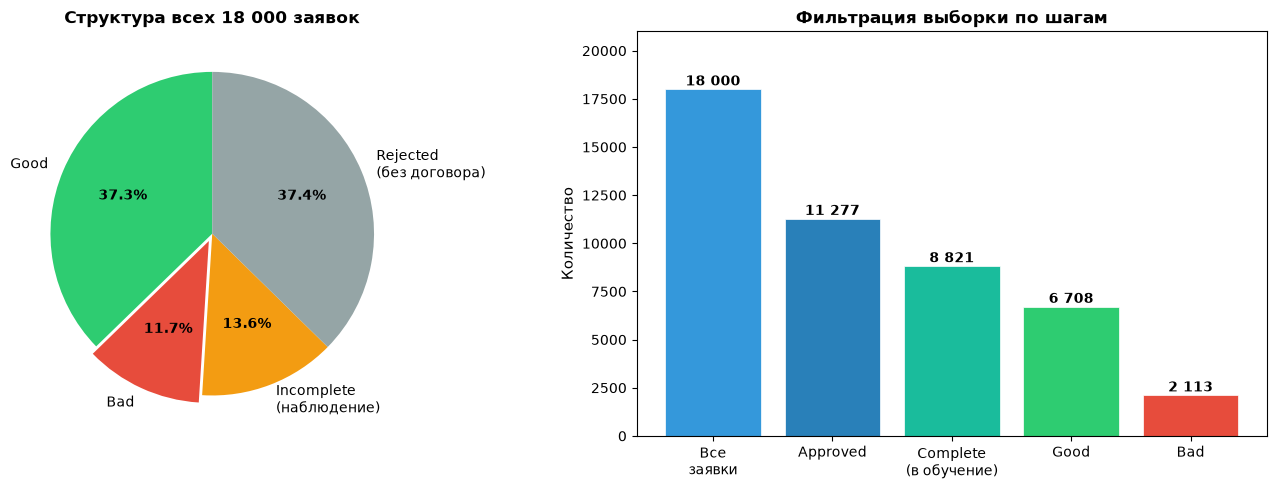

Good: 6708, Bad: 2113, Incomplete: 2456, Rejected: 6723
Используемая выборка для обучения: 8821 контрактов


In [21]:
# Баланс классов: Good / Bad / Rejected
n_good = int((complete['target'] == 0).sum())
n_bad = int(complete['target'].sum())
n_incomplete = int((contracted['observation_window'] == 'incomplete').sum())
n_rejected = int(target_df['contract_id'].isna().sum())

labels_target = ['Good', 'Bad', 'Incomplete\n(наблюдение)', 'Rejected\n(без договора)']
sizes_target = [n_good, n_bad, n_incomplete, n_rejected]
colors_target = ['#2ecc71', '#e74c3c', '#f39c12', '#95a5a6']
explode_target = (0, 0.05, 0, 0)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Pie chart
wedges, texts, autotexts = axes[0].pie(
    sizes_target, labels=labels_target, colors=colors_target,
    explode=explode_target, autopct='%1.1f%%', startangle=90,
    textprops={'fontsize': 10}
)
for at in autotexts:
    at.set_fontweight('bold')
axes[0].set_title('Структура всех 18 000 заявок', fontsize=12, fontweight='bold')

# Bar chart: используемая выборка
cats = ['Все\nзаявки', 'Approved', 'Complete\n(в обучение)', 'Good', 'Bad']
vals = [18000, 11277, 8821, n_good, n_bad]
bar_colors = ['#3498db', '#2980b9', '#1abc9c', '#2ecc71', '#e74c3c']
bars = axes[1].bar(cats, vals, color=bar_colors, edgecolor='white', linewidth=0.5)
for bar, val in zip(bars, vals):
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 200,
                 f'{val:,}'.replace(',', ' '), ha='center', fontsize=10, fontweight='bold')
axes[1].set_ylabel('Количество', fontsize=11)
axes[1].set_title('Фильтрация выборки по шагам', fontsize=12, fontweight='bold')
axes[1].set_ylim(0, 21000)

fig.tight_layout()
plt.show()

print(f'Good: {n_good}, Bad: {n_bad}, Incomplete: {n_incomplete}, Rejected: {n_rejected}')
print(f'Используемая выборка для обучения: {n_good + n_bad} контрактов')

### Обоснование параметров таргета

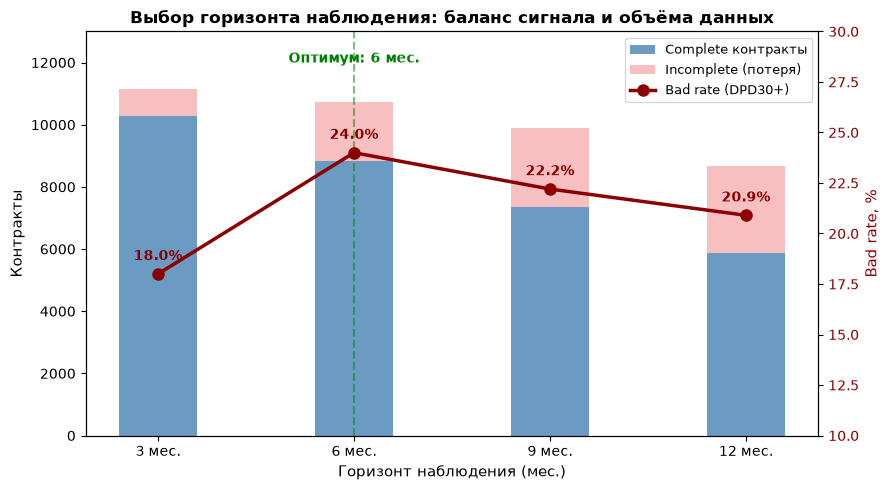

Вывод: 6 месяцев — оптимум. Bad rate максимален (24.0%), потеря данных приемлема (21.5%).
При 9 мес. теряем 34.5% данных, а bad rate падает до 22.2%.
При 3 мес. bad rate занижен (18.0%), т.к. часть bad ещё не проявилась.


In [22]:
# === График 1: Выбор горизонта наблюдения ===
horizons = [3, 6, 9, 12]
complete_counts = [10280, 8821, 7360, 5874]
bad_rates = [18.0, 24.0, 22.2, 20.9]
incomplete_pcts = [8.5, 21.5, 34.5, 47.7]

fig, ax1 = plt.subplots(figsize=(9, 5))
x = np.arange(len(horizons))
width = 0.4

bars = ax1.bar(x, complete_counts, width, color='steelblue', alpha=0.8, label='Complete контракты')
ax1.bar(x, [c * ip / 100 for c, ip in zip(complete_counts, incomplete_pcts)],
        width, bottom=complete_counts, color='lightcoral', alpha=0.5,
        label='Incomplete (потеря)')
ax1.set_ylabel('Контракты', fontsize=11)
ax1.set_xlabel('Горизонт наблюдения (мес.)', fontsize=11)
ax1.set_xticks(x)
ax1.set_xticklabels([f'{h} мес.' for h in horizons])
ax1.set_ylim(0, 13000)

ax2 = ax1.twinx()
ax2.plot(x, bad_rates, 'o-', color='darkred', linewidth=2.5, markersize=8, label='Bad rate (DPD30+)')
for i, (xr, br) in enumerate(zip(x, bad_rates)):
    ax2.annotate(f'{br}%', (xr, br), textcoords='offset points',
                 xytext=(0, 10), ha='center', fontsize=10, fontweight='bold', color='darkred')
ax2.set_ylabel('Bad rate, %', fontsize=11, color='darkred')
ax2.set_ylim(10, 30)
ax2.tick_params(axis='y', labelcolor='darkred')

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper right', fontsize=9)

ax1.axvline(x=1, color='green', linestyle='--', alpha=0.5, linewidth=1.5)
ax1.annotate('Оптимум: 6 мес.', xy=(1, 12000), fontsize=10,
             color='green', fontweight='bold', ha='center')

ax1.set_title('Выбор горизонта наблюдения: баланс сигнала и объёма данных', fontsize=12, fontweight='bold')
fig.tight_layout()
plt.show()

print('Вывод: 6 месяцев — оптимум. Bad rate максимален (24.0%), потеря данных приемлема (21.5%).')
print('При 9 мес. теряем 34.5% данных, а bad rate падает до 22.2%.')
print('При 3 мес. bad rate занижен (18.0%), т.к. часть bad ещё не проявилась.')

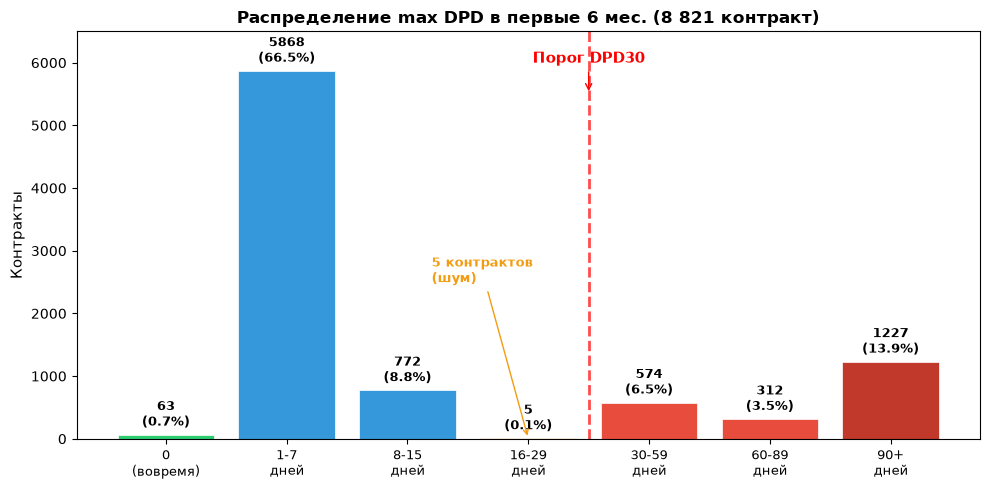

Вывод: провал между 16-29 днями (5 контрактов) и 30-59 днями (574) — чёткая граница.
DPD30 — стандартный порог (Basel II/III, МСФО 9), подтверждён структурой данных.


In [23]:
# === График 2: Выбор порога DPD ===
dpd_labels = ['0\n(вовремя)', '1-7\nдней', '8-15\nдней', '16-29\nдней', '30-59\nдней', '60-89\nдней', '90+\nдней']
dpd_counts = [63, 5868, 772, 5, 574, 312, 1227]
dpd_colors = ['#2ecc71', '#3498db', '#3498db', '#f39c12', '#e74c3c', '#e74c3c', '#c0392b']

fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.bar(range(len(dpd_labels)), dpd_counts, color=dpd_colors, edgecolor='white', linewidth=0.5)

for bar, count in zip(bars, dpd_counts):
    pct = round(100 * count / sum(dpd_counts), 1)
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 80,
            f'{count}\n({pct}%)', ha='center', va='bottom', fontsize=9, fontweight='bold')

ax.axvline(x=3.5, color='red', linestyle='--', linewidth=2, alpha=0.7)
ax.annotate('Порог DPD30', xy=(3.5, 5500), fontsize=11, fontweight='bold',
            color='red', ha='center',
            arrowprops=dict(arrowstyle='->', color='red'),
            xytext=(3.5, 6000))

ax.set_xticks(range(len(dpd_labels)))
ax.set_xticklabels(dpd_labels, fontsize=9)
ax.set_ylabel('Контракты', fontsize=11)
ax.set_title('Распределение max DPD в первые 6 мес. (8 821 контракт)', fontsize=12, fontweight='bold')
ax.set_ylim(0, 6500)

ax.annotate('5 контрактов\n(шум)', xy=(3, 5), xytext=(2.2, 2500),
            fontsize=9, color='#f39c12', fontweight='bold',
            arrowprops=dict(arrowstyle='->', color='#f39c12'))

fig.tight_layout()
plt.show()

print('Вывод: провал между 16-29 днями (5 контрактов) и 30-59 днями (574) — чёткая граница.')
print('DPD30 — стандартный порог (Basel II/III, МСФО 9), подтверждён структурой данных.')

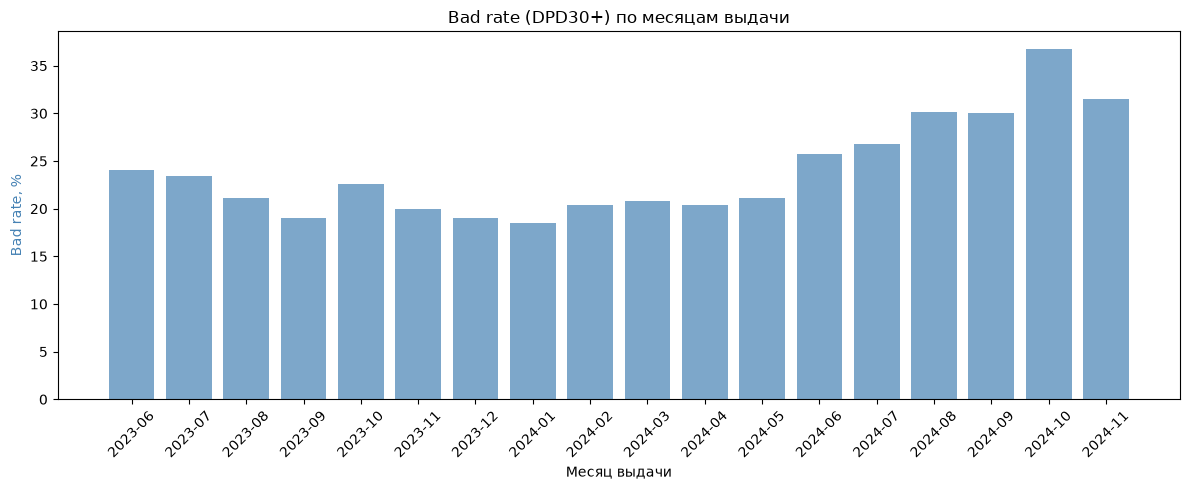

decision_month  total   bad  bad_rate_pct
       2023-06    482 116.0     24.066390
       2023-07    482 113.0     23.443983
       2023-08    512 108.0     21.093750
       2023-09    488  93.0     19.057377
       2023-10    530 120.0     22.641509
       2023-11    466  93.0     19.957082
       2023-12    505  96.0     19.009901
       2024-01    471  87.0     18.471338
       2024-02    477  97.0     20.335430
       2024-03    509 106.0     20.825147
       2024-04    447  91.0     20.357942
       2024-05    548 116.0     21.167883
       2024-06    481 124.0     25.779626
       2024-07    519 139.0     26.782274
       2024-08    497 150.0     30.181087
       2024-09    439 132.0     30.068337
       2024-10    514 189.0     36.770428
       2024-11    454 143.0     31.497797


In [24]:
# Bad rate по месяцам выдачи
complete['decision_month'] = pd.to_datetime(complete['decision_date']).dt.to_period('M')
bad_by_month = complete.groupby('decision_month').agg(
    total=('target', 'count'),
    bad=('target', 'sum'),
    bad_rate=('target', 'mean')
).reset_index()
bad_by_month['bad_rate_pct'] = bad_by_month['bad_rate'] * 100

fig, ax1 = plt.subplots(figsize=(12, 5))
ax1.bar(bad_by_month['decision_month'].astype(str), bad_by_month['bad_rate_pct'], color='steelblue', alpha=0.7)
ax1.set_ylabel('Bad rate, %', color='steelblue')
ax1.set_xlabel('Месяц выдачи')
ax1.tick_params(axis='x', rotation=45)
ax1.set_title('Bad rate (DPD30+) по месяцам выдачи')
plt.tight_layout()
plt.show()

print(bad_by_month[['decision_month', 'total', 'bad', 'bad_rate_pct']].to_string(index=False))

## Шаг 4. Анализ проблемы

In [25]:
# Сводная таблица: Approved vs Rejected
stats_rows = []
for col in ['requested_amount_uzs', 'declared_income_uzs', 'employment_months', 'term_months']:
    r = q(f"""
    SELECT
        ROUND(AVG({col}) FILTER (WHERE final_decision='approved')::numeric, 0) as avg_approved,
        ROUND(AVG({col}) FILTER (WHERE final_decision='rejected')::numeric, 0) as avg_rejected,
        ROUND(PERCENTILE_CONT(0.5) WITHIN GROUP (ORDER BY {col}) FILTER (WHERE final_decision='approved')::numeric, 0) as med_approved,
        ROUND(PERCENTILE_CONT(0.5) WITHIN GROUP (ORDER BY {col}) FILTER (WHERE final_decision='rejected')::numeric, 0) as med_rejected
    FROM scoring_applications
""")
    r['field'] = col
    stats_rows.append(r)

stats_df = pd.concat(stats_rows, ignore_index=True)
stats_df = stats_df[['field', 'avg_approved', 'avg_rejected', 'med_approved', 'med_rejected']]
stats_df['diff_pct'] = ((stats_df['avg_approved'].astype(float) - stats_df['avg_rejected'].astype(float))
                        / stats_df['avg_rejected'].astype(float) * 100).round(1)

print('=== Сравнение Approved vs Rejected ===')
print(stats_df.to_string(index=False))

# Аномалии
print('\n=== Аномалии ===')
anomalies = q("""
SELECT
    COUNT(*) FILTER (WHERE declared_income_uzs = 0) as income_zero,
    COUNT(*) FILTER (WHERE employment_months = 0) as employment_zero,
    COUNT(*) FILTER (WHERE requested_amount_uzs > declared_income_uzs * 12) as amount_gt_12x_income,
    COUNT(*) FILTER (WHERE employment_months IS NULL) as employment_null
FROM scoring_applications
""")
print(anomalies.to_string(index=False))

=== Сравнение Approved vs Rejected ===
               field  avg_approved  avg_rejected  med_approved  med_rejected  diff_pct
requested_amount_uzs    13718267.0    10779161.0    10600000.0     6600000.0      27.3
 declared_income_uzs    10192486.0     6384541.0     8090000.0     3830000.0      59.6
   employment_months         120.0         121.0         121.0         122.0      -0.8
         term_months          14.0          13.0          12.0          12.0       7.7

=== Аномалии ===
 income_zero  employment_zero  amount_gt_12x_income  employment_null
           0               63                    16             1402


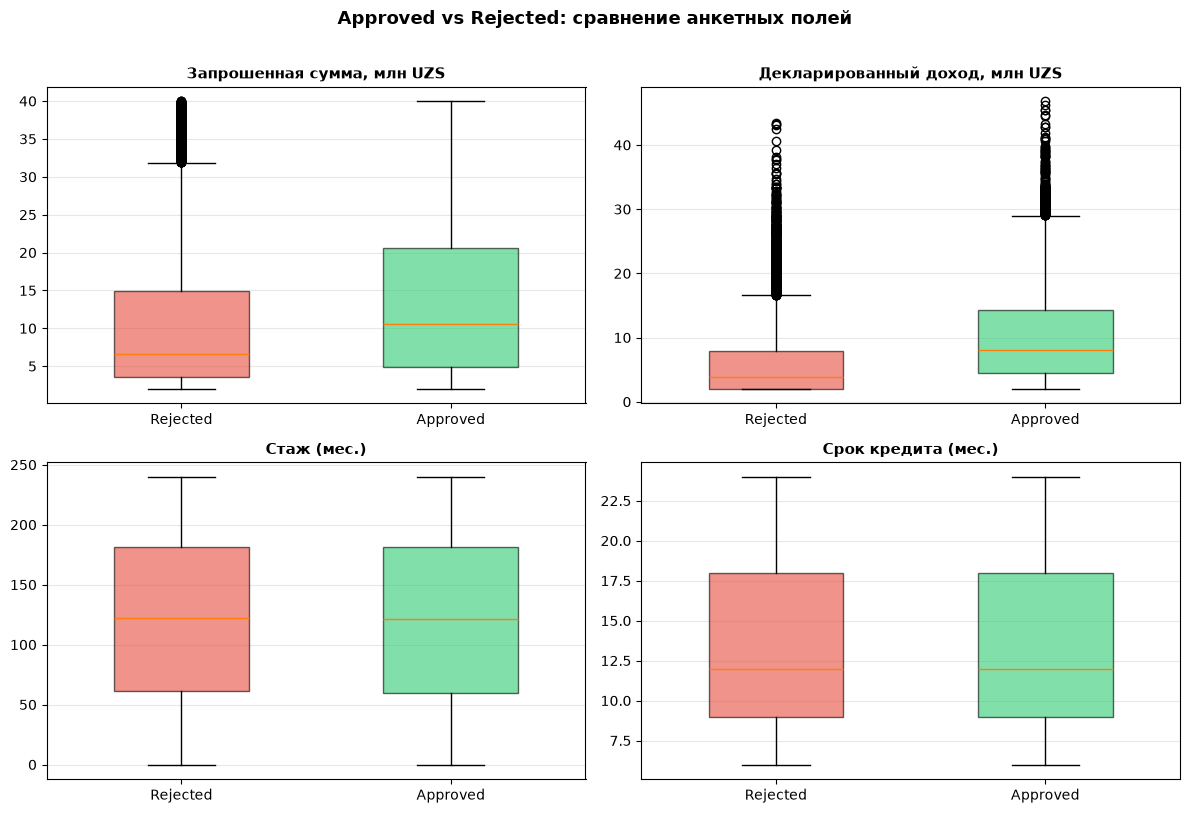

Вывод: одобренные получают суммы выше (+27%), доход выше (+60%), стаж и срок сопоставимы.


In [26]:
# Approved vs Rejected: boxplot-ы по 4 полям
plot_data = q("""SELECT final_decision,
    requested_amount_uzs / 1e6 as amount_mln,
    declared_income_uzs / 1e6 as income_mln,
    employment_months,
    term_months
FROM scoring_applications""")

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
plot_cols = [('amount_mln', 'Запрошенная сумма, млн UZS'),
             ('income_mln', 'Декларированный доход, млн UZS'),
             ('employment_months', 'Стаж (мес.)'),
             ('term_months', 'Срок кредита (мес.)')]

for ax, (col, title) in zip(axes.flat, plot_cols):
    approved = plot_data[plot_data['final_decision'] == 'approved'][col].dropna()
    rejected = plot_data[plot_data['final_decision'] == 'rejected'][col].dropna()
    bp = ax.boxplot([rejected, approved], tick_labels=['Rejected', 'Approved'],
                    patch_artist=True, widths=0.5)
    bp['boxes'][0].set_facecolor('#e74c3c')
    bp['boxes'][1].set_facecolor('#2ecc71')
    for box in bp['boxes']:
        box.set_alpha(0.6)
    ax.set_title(title, fontsize=11, fontweight='bold')
    ax.grid(axis='y', alpha=0.3)

fig.suptitle('Approved vs Rejected: сравнение анкетных полей', fontsize=13, fontweight='bold', y=1.01)
fig.tight_layout()
plt.show()

print('Вывод: одобренные получают суммы выше (+27%), доход выше (+60%), стаж и срок сопоставимы.')

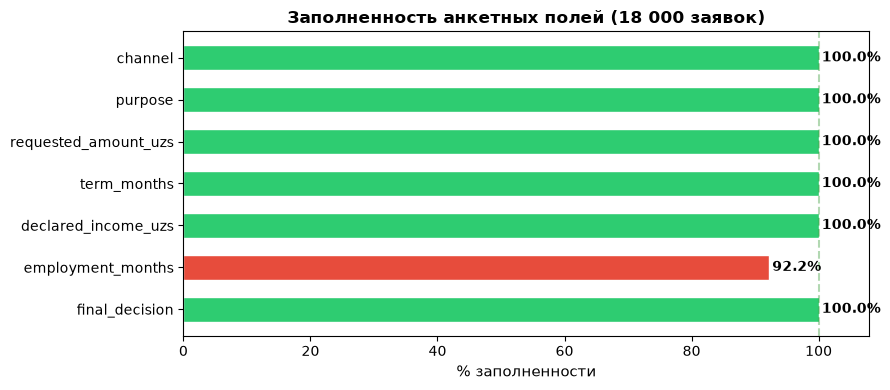

Вывод: все поля заполнены на 100%, кроме employment_months (92.2% — 1 402 пропуска).


In [27]:
# Пропуски в анкетных полях
fields = ['channel', 'purpose', 'requested_amount_uzs', 'term_months',
          'declared_income_uzs', 'employment_months', 'final_decision']
fill_pcts = [100.0, 100.0, 100.0, 100.0, 100.0, 92.2, 100.0]

fig, ax = plt.subplots(figsize=(9, 4))
colors = ['#2ecc71' if p == 100.0 else '#e74c3c' for p in fill_pcts]
bars = ax.barh(fields[::-1], fill_pcts[::-1], color=colors[::-1], edgecolor='white', height=0.6)

for bar, pct in zip(bars, fill_pcts[::-1]):
    ax.text(bar.get_width() + 0.5, bar.get_y() + bar.get_height()/2,
            f'{pct}%', va='center', fontsize=10, fontweight='bold')

ax.set_xlim(0, 108)
ax.axvline(x=100, color='green', linestyle='--', alpha=0.3)
ax.set_xlabel('% заполненности', fontsize=11)
ax.set_title('Заполненность анкетных полей (18 000 заявок)', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

print('Вывод: все поля заполнены на 100%, кроме employment_months (92.2% — 1 402 пропуска).')

## Шаг 5. Фичи (только до decision_date)

In [28]:
# === Анкетные фичи ===
features_sql = """
SELECT
    a.application_id, a.client_id, a.decision_date, a.final_decision,
    a.requested_amount_uzs, a.term_months, a.declared_income_uzs, a.employment_months,
    a.channel, a.purpose,
    bs.bureau_score, bs.existing_debt_uzs, bs.active_loans_cnt,
    bi.inquiries_3m,
    bl.worst_dpd_ever, bl.total_outstanding, bl.active_loans_bureau
FROM scoring_applications a
LEFT JOIN LATERAL (
    SELECT bureau_score, existing_debt_uzs, active_loans_cnt
    FROM scoring_bureau_snapshots
    WHERE client_id = a.client_id AND snapshot_date <= a.decision_date
    ORDER BY snapshot_date DESC LIMIT 1
) bs ON TRUE
LEFT JOIN (
    SELECT client_id, COUNT(*) as inquiries_3m
    FROM scoring_bureau_inquiries
    GROUP BY client_id
) bi ON bi.client_id = a.client_id
LEFT JOIN (
    SELECT client_id,
        MAX(worst_dpd_ever) as worst_dpd_ever,
        SUM(outstanding_uzs) as total_outstanding,
        COUNT(*) FILTER (WHERE status IN ('active', 'open')) as active_loans_bureau
    FROM scoring_bureau_loans
    GROUP BY client_id
) bl ON bl.client_id = a.client_id
ORDER BY a.decision_date
"""

features_df = q(features_sql)
print(f'Features shape: {features_df.shape}')
print(features_df.head(5).to_string(index=False))
print('\nNull %:')
print((features_df.isnull().sum() / len(features_df) * 100).round(1))

Features shape: (18000, 17)
 application_id  client_id decision_date final_decision  requested_amount_uzs  term_months  declared_income_uzs  employment_months    channel  purpose  bureau_score  existing_debt_uzs  active_loans_cnt  inquiries_3m  worst_dpd_ever  total_outstanding  active_loans_bureau
          13624      26897    2023-06-01       rejected               6000000            9              2870000              211.0     branch    other           NaN                NaN               NaN           NaN             NaN                NaN                  NaN
          11687      25699    2023-06-01       approved              10200000           12             10450000               45.0 mobile_app    other           NaN                NaN               NaN           NaN             NaN                NaN                  NaN
           5396       1813    2023-06-01       approved               4400000            9              3430000               90.0      agent   repair      

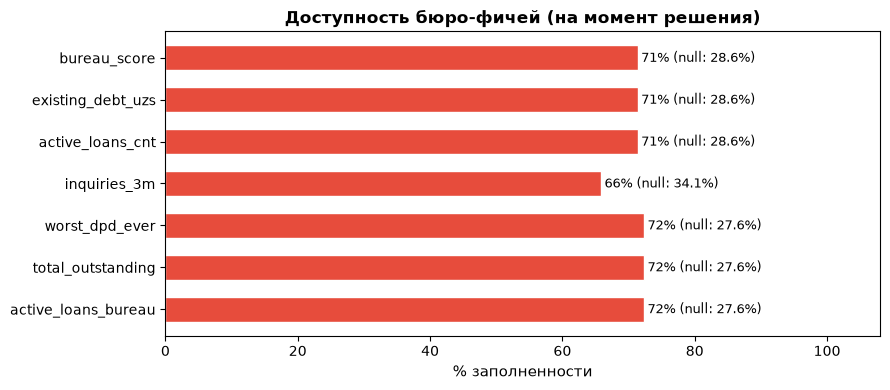

Вывод: bureau_score доступен для ~66% заявок. Остальные бюро-фичи — аналогично.
Причина: не все клиенты имеют записи в бюро (новые клиенты, Thin-file).


In [29]:
# Пропуски в бюро-фичах
bureau_cols = ['bureau_score', 'existing_debt_uzs', 'active_loans_cnt',
               'inquiries_3m', 'worst_dpd_ever', 'total_outstanding', 'active_loans_bureau']
bureau_nulls = [features_df[c].isnull().sum() / len(features_df) * 100 for c in bureau_cols]

fig, ax = plt.subplots(figsize=(9, 4))
colors_b = ['#e74c3c' if n > 20 else '#f39c12' if n > 5 else '#2ecc71' for n in bureau_nulls]
bars = ax.barh(bureau_cols[::-1], [100 - n for n in bureau_nulls[::-1]],
               color=colors_b[::-1], edgecolor='white', height=0.6)

for bar, null_pct in zip(bars, bureau_nulls[::-1]):
    ax.text(bar.get_width() + 0.5, bar.get_y() + bar.get_height()/2,
            f'{100-null_pct:.0f}% (null: {null_pct:.1f}%)', va='center', fontsize=9)

ax.set_xlim(0, 108)
ax.set_xlabel('% заполненности', fontsize=11)
ax.set_title('Доступность бюро-фичей (на момент решения)', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

print('Вывод: bureau_score доступен для ~66% заявок. Остальные бюро-фичи — аналогично.')
print('Причина: не все клиенты имеют записи в бюро (новые клиенты, Thin-file).')

In [30]:
# === Карточные фичи за 3-6 мес до подачи ===
card_features_sql = """
SELECT
    a.application_id,
    COUNT(DISTINCT ct.client_id) as has_txn,
    SUM(ct.amount_uzs) as total_txn_amount,
    COUNT(*) as txn_count,
    COUNT(*) FILTER (WHERE ct.status = 'declined') as declined_count,
    ROUND(100.0 * COUNT(*) FILTER (WHERE ct.status = 'declined') / NULLIF(COUNT(*), 0), 1) as decline_rate,
    SUM(ct.amount_uzs) FILTER (WHERE ct.mcc_group IN ('salary', 'transfer_in')) as income_txn_total,
    COUNT(*) FILTER (WHERE ct.txn_type = 'cash_withdrawal') as cash_withdrawal_cnt,
    SUM(ct.amount_uzs) FILTER (WHERE ct.txn_type = 'cash_withdrawal') as cash_withdrawal_amt
FROM scoring_applications a
JOIN scoring_contracts c ON a.application_id = c.application_id
LEFT JOIN scoring_card_transactions ct
    ON ct.client_id = a.client_id
    AND ct.txn_ts >= (c.issue_date - INTERVAL '6 months')::timestamp
    AND ct.txn_ts < a.decision_date::timestamp
GROUP BY a.application_id
"""

card_df = q(card_features_sql)
print(f'Card features shape: {card_df.shape}')
print(card_df.head(5).to_string(index=False))
print(f'\nКлиентов с транзакциями: {card_df["has_txn"].sum()} из {len(card_df)}')

Card features shape: (11277, 9)
 application_id  has_txn  total_txn_amount  txn_count  declined_count  decline_rate income_txn_total  cash_withdrawal_cnt cash_withdrawal_amt
              1        1        49673612.0         39               3           7.7             None                    0                None
              2        1         7388912.0         32               1           3.1             None                    0                None
              3        0               NaN          1               0           0.0             None                    0                None
              7        1        40466269.0         45               2           4.4             None                    0                None
             10        1        67953668.0         38               0           0.0             None                    0                None

Клиентов с транзакциями: 5549 из 11277


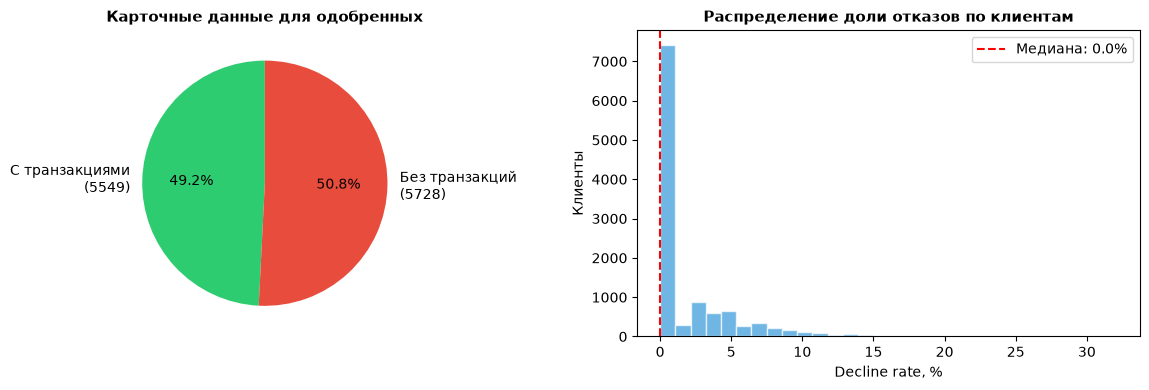

Медиана decline_rate: 0.0%
Средний decline_rate: 1.9%


In [31]:
# Покрытие карточными данными
n_with_txn = int(card_df['has_txn'].sum())
n_without_txn = len(card_df) - n_with_txn

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Pie: покрытие
axes[0].pie([n_with_txn, n_without_txn],
            labels=[f'С транзакциями\n({n_with_txn})', f'Без транзакций\n({n_without_txn})'],
            colors=['#2ecc71', '#e74c3c'], autopct='%1.1f%%', startangle=90,
            textprops={'fontsize': 10})
axes[0].set_title('Карточные данные для одобренных', fontsize=11, fontweight='bold')

# Decline rate distribution (только клиенты с транзакциями)
decline_data = card_df[card_df['decline_rate'].notna()]['decline_rate']
axes[1].hist(decline_data, bins=30, color='#3498db', edgecolor='white', alpha=0.7)
axes[1].axvline(x=decline_data.median(), color='red', linestyle='--', linewidth=1.5,
                label=f'Медиана: {decline_data.median():.1f}%')
axes[1].set_xlabel('Decline rate, %')
axes[1].set_ylabel('Клиенты')
axes[1].set_title('Распределение доли отказов по клиентам', fontsize=11, fontweight='bold')
axes[1].legend()

fig.tight_layout()
plt.show()

print(f'Медиана decline_rate: {decline_data.median():.1f}%')
print(f'Средний decline_rate: {decline_data.mean():.1f}%')

**Колонки-ловушки (будущая информация):**
1. `dpd_max` из `scoring_applications_full` — максимальная просрочка после выдачи, недоступна до решения
2. `contract_status_now` из `scoring_applications_full` — текущий статус договора, формируется после выдачи
3. `collection_calls_cnt` из `scoring_applications_full` — звонки коллекторов, следствие просрочки

## Шаг 6. Схема проверки

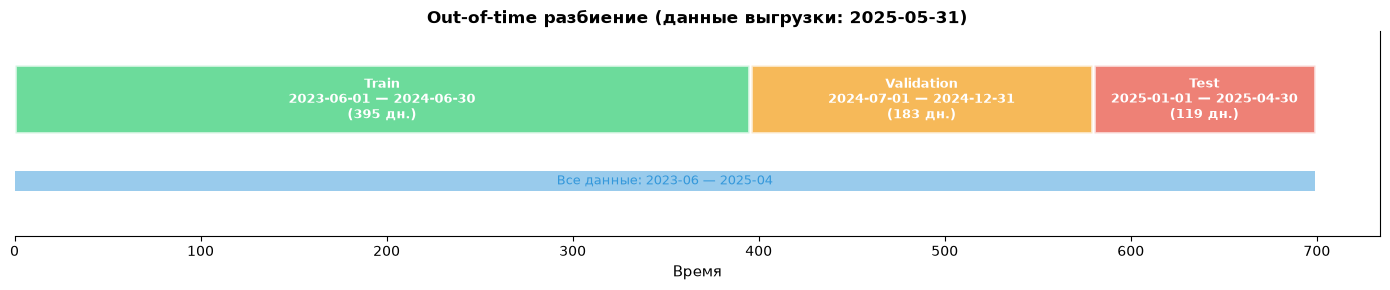

Train: 2023-06 → 2024-06 (~12 мес., ~10 000 заявок)
Validation: 2024-07 → 2024-12 (6 мес., ~5 000 заявок)
Test: 2025-01 → 2025-04 (4 мес., ~3 000 заявок)

Разбиение только по времени, без случайного смешивания — имитация реального скора.


In [32]:
# Временна́я разбивка: train / val / test
fig, ax = plt.subplots(figsize=(14, 3))

periods = [
    ('Train', '2023-06-01', '2024-06-30', '#2ecc71'),
    ('Validation', '2024-07-01', '2024-12-31', '#f39c12'),
    ('Test', '2025-01-01', '2025-04-30', '#e74c3c'),
]

for i, (label, start, end, color) in enumerate(periods):
    s = pd.to_datetime(start)
    e = pd.to_datetime(end)
    ax.barh(0, (e - s).days, left=(s - pd.to_datetime('2023-06-01')).days,
            height=0.5, color=color, alpha=0.7, edgecolor='white', linewidth=2)
    mid = (s - pd.to_datetime('2023-06-01')).days + (e - s).days / 2
    days = (e - s).days
    ax.text(mid, 0, f'{label}\n{start} — {end}\n({days} дн.)',
            ha='center', va='center', fontsize=9, fontweight='bold', color='white')

# Вся линия данных
ax.barh(-0.6, (pd.to_datetime('2025-04-30') - pd.to_datetime('2023-06-01')).days,
        left=0, height=0.15, color='#3498db', alpha=0.5)
ax.text((pd.to_datetime('2025-04-30') - pd.to_datetime('2023-06-01')).days / 2, -0.6,
        'Все данные: 2023-06 — 2025-04', ha='center', va='center', fontsize=9, color='#3498db')

ax.set_ylim(-1, 0.5)
ax.set_yticks([])
ax.set_xlabel('Время', fontsize=11)
ax.set_title('Out-of-time разбиение (данные выгрузки: 2025-05-31)', fontsize=12, fontweight='bold')
ax.spines['top'].set_visible(False)
ax.spines['left'].set_visible(False)
plt.tight_layout()
plt.show()

print('Train: 2023-06 → 2024-06 (~12 мес., ~10 000 заявок)')
print('Validation: 2024-07 → 2024-12 (6 мес., ~5 000 заявок)')
print('Test: 2025-01 → 2025-04 (4 мес., ~3 000 заявок)')
print('\nРазбиение только по времени, без случайного смешивания — имитация реального скора.')

**Метрики:**
- Ранжирование: KS-statistic, AUC-ROC, Gini
- Экономика: profit/loss на среднем договоре

**Цена ошибок (пример):**
- **FN (одобрили bad):** потеря ≈ issued_amount × % невозврата + издержки взыскания
- **FP (отклонили good):** потеря = упущенная маржа = annuity × term × margin

Пример: средний договор ~15 млн UZS, маржа ~5%, срок 12 мес. → FP ≈ 15M × 5% = 750K UZS.
FN: 15M × 30% невозврата = 4.5M UZS. → FN дороже FP в ~6 раз → нужен Recall > Precision.